In [71]:
import random
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from PIL import Image


In [72]:
# AMP + deterministic seeds
use_amp = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)


C:\Users\rupes\AppData\Local\Temp\ipykernel_18868\3096111476.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


In [73]:
# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [74]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


In [75]:
# Dataset paths
base_dir = r"D:\Work-Projects\Skin Cancer Detection\combined_isic_binary"
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')


In [76]:
# Quick dataset check (manifest-based)
from pathlib import Path
OUT_ROOT = Path('combined_isic_binary')
train_df = pd.read_csv(OUT_ROOT / 'train.csv')
val_df = pd.read_csv(OUT_ROOT / 'val.csv')
test_df = pd.read_csv(OUT_ROOT / 'test.csv')
print('Train counts:', train_df['label_name'].value_counts())
print('Val counts:', val_df['label_name'].value_counts())
print('Test counts:', test_df['label_name'].value_counts())


Train counts: label_name
benign       4018
malignant    3335
Name: count, dtype: int64
Val counts: label_name
benign       861
malignant    715
Name: count, dtype: int64
Test counts: label_name
benign       861
malignant    715
Name: count, dtype: int64


In [77]:
# Image parameters
img_size = 224
batch_size = 32
num_classes = 2
num_epochs = 80
patience = 12


In [78]:
# Compute dataset mean/std (train split only) using manifest
base_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor()
])

base_dataset = ManifestDataset(train_df, OUT_ROOT, transform=base_transform)
base_loader = DataLoader(base_dataset, batch_size=64, shuffle=False)

n_pixels = 0
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)

for imgs, _ in base_loader:
    n_pixels += imgs.numel() / 3
    channel_sum += imgs.sum(dim=[0, 2, 3])
    channel_sum_sq += (imgs ** 2).sum(dim=[0, 2, 3])

mean = (channel_sum / n_pixels).tolist()
std = (channel_sum_sq / n_pixels - torch.tensor(mean) ** 2).sqrt().tolist()
print('Mean:', mean)
print('Std:', std)


Mean: [0.701930820941925, 0.5246617794036865, 0.4899868965148926]
Std: [0.19448547065258026, 0.19188180565834045, 0.206537127494812]


In [79]:
# Data augmentation and normalization
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(img_size),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


In [80]:
from PIL import Image
from torch.utils.data import Dataset
# Combined manifest-based dataset (no random aug on val/test)
from pathlib import Path

OUT_ROOT = Path("combined_isic_binary")
train_csv = OUT_ROOT / "train.csv"
val_csv = OUT_ROOT / "val.csv"
test_csv = OUT_ROOT / "test.csv"

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

class_names = ["benign", "malignant"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

class ManifestDataset(Dataset):
    def __init__(self, df, root: Path, transform=None):
        self.df = df.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.root / row["filepath"]
        img = Image.open(img_path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = int(row["label"])
        return img, label

train_data = ManifestDataset(train_df, OUT_ROOT, transform=train_transforms)
val_data = ManifestDataset(val_df, OUT_ROOT, transform=val_test_transforms)
test_data = ManifestDataset(test_df, OUT_ROOT, transform=val_test_transforms)

train_targets = train_df["label"].values
print("Train/Val/Test:", len(train_data), len(val_data), len(test_data))
print("Train counts:", train_df["label_name"].value_counts())


Train/Val/Test: 7353 1576 1576
Train counts: label_name
benign       4018
malignant    3335
Name: count, dtype: int64


In [81]:
# Dataloaders
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [84]:
# Define custom CNN with residual blocks
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        out = self.relu(out)
        return out

class CustomResNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer1 = nn.Sequential(
            BasicBlock(32, 32),
            BasicBlock(32, 32)
        )
        self.layer2 = nn.Sequential(
            BasicBlock(32, 64, stride=2),
            BasicBlock(64, 64)
        )
        self.layer3 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128)
        )
        self.layer4 = nn.Sequential(
            BasicBlock(128, 256, stride=2),
            BasicBlock(256, 256)
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

model = CustomResNet(num_classes=num_classes).to(device)


In [85]:
# Loss, optimizer, scheduler
train_targets = train_df["label"].values
class_counts = np.bincount(train_targets)
class_weights = 1.0 / class_counts
class_weights_t = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.02)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)


In [86]:
# Training loop with early stopping (monitor val loss)
best_val_loss = float('inf')
counter = 0
train_acc_hist, val_acc_hist = [], []
train_loss_hist, val_loss_hist = [], []

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    train_acc_hist.append(train_acc.item())
    val_acc_hist.append(val_acc.item())
    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'skin_lesions_model_custom-c.pth')
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping.")
            break

# Load best model
model.load_state_dict(torch.load('skin_lesions_model_custom-c.pth'))


Epoch 1/80, Train Acc: 0.7034, Val Acc: 0.7697, Val Loss: 0.5155
Epoch 2/80, Train Acc: 0.7280, Val Acc: 0.7652, Val Loss: 0.5382
Epoch 3/80, Train Acc: 0.7325, Val Acc: 0.7652, Val Loss: 0.5097
Epoch 4/80, Train Acc: 0.7362, Val Acc: 0.7538, Val Loss: 0.5177
Epoch 5/80, Train Acc: 0.7450, Val Acc: 0.6878, Val Loss: 0.6781
Epoch 6/80, Train Acc: 0.7465, Val Acc: 0.7989, Val Loss: 0.4777
Epoch 7/80, Train Acc: 0.7628, Val Acc: 0.8115, Val Loss: 0.4600
Epoch 8/80, Train Acc: 0.7725, Val Acc: 0.8077, Val Loss: 0.4737
Epoch 9/80, Train Acc: 0.7800, Val Acc: 0.8230, Val Loss: 0.4161
Epoch 10/80, Train Acc: 0.7834, Val Acc: 0.8065, Val Loss: 0.4813
Epoch 11/80, Train Acc: 0.7937, Val Acc: 0.8223, Val Loss: 0.4189
Epoch 12/80, Train Acc: 0.7922, Val Acc: 0.8236, Val Loss: 0.4178
Epoch 13/80, Train Acc: 0.7944, Val Acc: 0.8338, Val Loss: 0.4161
Epoch 14/80, Train Acc: 0.8031, Val Acc: 0.8331, Val Loss: 0.4043
Epoch 15/80, Train Acc: 0.8023, Val Acc: 0.8261, Val Loss: 0.4061
Epoch 16/80, Train 

<All keys matched successfully>

In [87]:
# Test evaluation
model.eval()
test_correct = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        test_correct += torch.sum(preds == labels.data)

test_acc = test_correct.double() / len(test_loader.dataset)
print(f"Test Accuracy: {test_acc:.4f}")


Test Accuracy: 0.8477


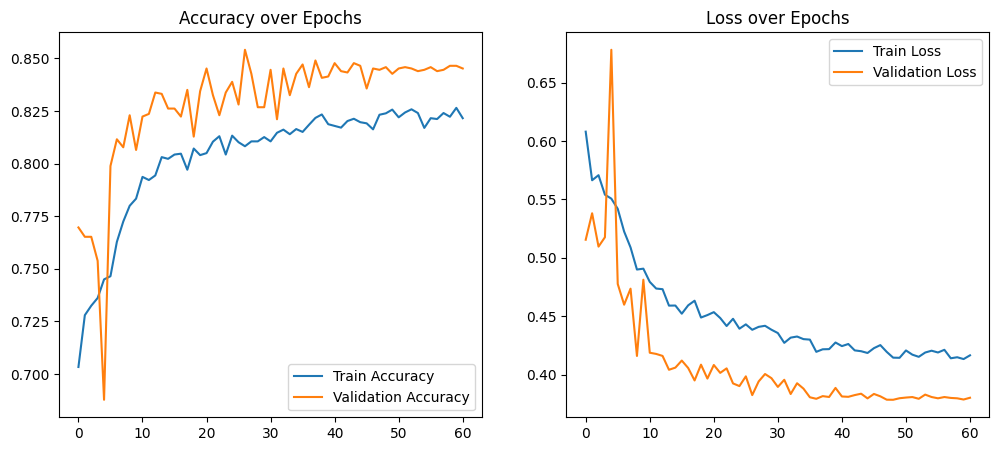

In [88]:
# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_acc_hist, label='Train Accuracy')
plt.plot(val_acc_hist, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_loss_hist, label='Train Loss')
plt.plot(val_loss_hist, label='Validation Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()


In [89]:
# Recreate model structure before loading weights
model = CustomResNet(num_classes=2)
model.load_state_dict(torch.load('skin_lesions_model_custom.pth'))
model.to(device)
model.eval()


CustomResNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (rel

In [95]:
# Sample prediction (optional)
# Use one image from the combined test manifest
sample_row = test_df.iloc[0]
image_path = str(OUT_ROOT / sample_row["filepath"])
label, confidence = predict_image(image_path, model)
print(f"Sample image: {image_path}")
print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")


Sample image: combined_isic_binary\images\sallyibrahim__ISIC_3724089_640x427.jpg
Prediction: benign (92.25% confidence)


In [97]:
image_path = r"D:\Work-Projects\Skin Cancer Detection\combined_isic_binary\images\fanconic__9.jpg"
label, confidence = predict_image(image_path, model)
print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")


Prediction: benign (83.18% confidence)


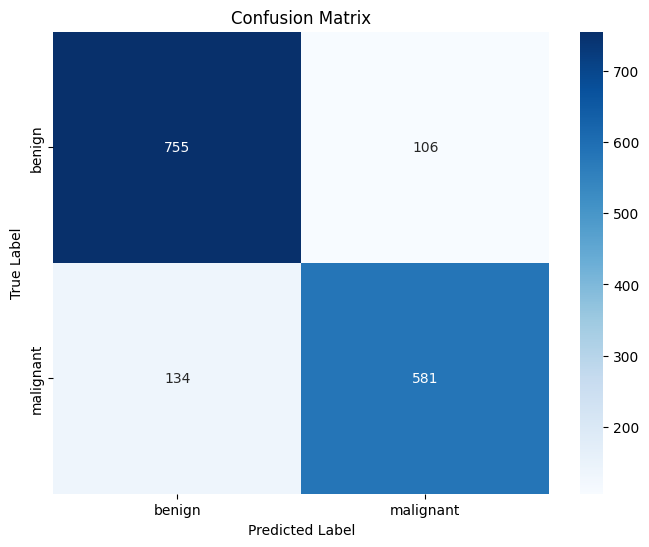

In [98]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [99]:
print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      benign       0.85      0.88      0.86       861
   malignant       0.85      0.81      0.83       715

    accuracy                           0.85      1576
   macro avg       0.85      0.84      0.85      1576
weighted avg       0.85      0.85      0.85      1576



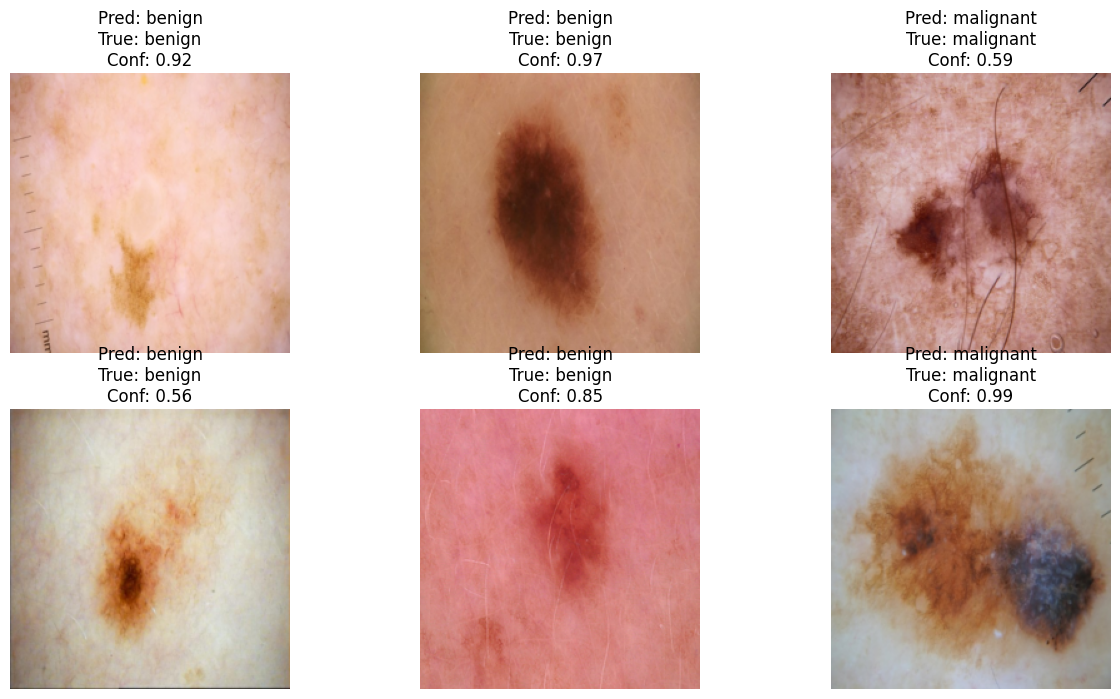

In [100]:
def visualize_predictions(model, data_loader, num_images=6):
    model.eval()
    images_shown = 0
    plt.figure(figsize=(15, 8))

    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(probs, 1)

            for i in range(imgs.size(0)):
                if images_shown == num_images:
                    return
                image = imgs[i].cpu().permute(1, 2, 0).numpy()
                image = (image * np.array(std)) + np.array(mean)
                image = np.clip(image, 0, 1)
                plt.subplot(2, 3, images_shown+1)
                plt.imshow(image)
                plt.axis('off')
                plt.title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}\nConf: {probs[i][preds[i]]:.2f}")
                images_shown += 1

visualize_predictions(model, test_loader)


In [101]:
# Evaluation + plots + save outputs
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
import json

OUT_FIG = OUT_ROOT / "figures"
OUT_FIG.mkdir(parents=True, exist_ok=True)

model.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(imgs)
        probs = torch.softmax(logits, dim=1)[:, 1]  # malignant prob
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

probs = np.concatenate(all_probs)
y_true = np.concatenate(all_labels)
y_pred = (probs >= 0.5).astype(int)

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, probs)
pr_auc = average_precision_score(y_true, probs)

print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4,4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix (Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.tight_layout()
plt.savefig(OUT_FIG / "confusion_matrix.png", dpi=300)
plt.close()

# ROC
fpr, tpr, _ = roc_curve(y_true, probs)
plt.figure(figsize=(4,4))
plt.plot(fpr, tpr, label=f"AUC={roc_auc:.4f}")
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_FIG / "roc_curve.png", dpi=300)
plt.close()

# PR
pr, rc, _ = precision_recall_curve(y_true, probs)
plt.figure(figsize=(4,4))
plt.plot(rc, pr, label=f"AP={pr_auc:.4f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("PR Curve")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_FIG / "pr_curve.png", dpi=300)
plt.close()

# Save outputs
(OUT_ROOT / "preds_test.csv").write_text(
    "prob_malignant,label\n" + "\n".join([f"{p:.6f},{y}" for p,y in zip(probs, y_true)]),
    encoding="utf-8"
)

results = {
    "accuracy": float(acc),
    "precision": float(prec),
    "recall": float(rec),
    "f1": float(f1),
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc),
}
(OUT_ROOT / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")


C:\Users\rupes\AppData\Local\Temp\ipykernel_18868\2788199523.py:20: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Accuracy: 0.8471
Precision: 0.8445
Recall: 0.8126
F1: 0.8282
ROC-AUC: 0.9157
PR-AUC: 0.9143


194